<a href="https://colab.research.google.com/github/StrawEater/AI4Animation/blob/master/Laboratorio_1_Hough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Imagenes de monedas

Para la seccion de monedas necesitamos las fotos. Esta celda las descarga de GitHub (funciona en Colab y localmente) y las deja en la carpeta `imagenes_monedas`. Si la carpeta ya existe no vuelve a descargar nada.

In [ ]:
#@title Descargar las imagenes de monedas { display-mode: "form" }
import io as _io
import os
import urllib.request
import zipfile

REPOSITORIO_URL = "https://github.com/Elementos-Reconocimiento-Visual-UBA/PracticasERV_2026_4toBim"  #@param {type:"string"}
RAMA = "main"  #@param {type:"string"}
CARPETA_EN_REPOSITORIO = "Laboratorio_1_Hough/imagenes_monedas"  #@param {type:"string"}
CARPETA_IMAGENES = "imagenes_monedas"  # carpeta local donde quedan las imagenes

def descargar_carpeta_de_github(url_zip, carpeta_en_repositorio, carpeta_local):
  # El zip de GitHub tiene todo dentro de una carpeta raiz: <repo>-<rama>/<carpeta_en_repositorio>/archivo
  with urllib.request.urlopen(url_zip) as respuesta:
    zip_repositorio = zipfile.ZipFile(_io.BytesIO(respuesta.read()))

  os.makedirs(carpeta_local, exist_ok=True)
  for nombre in zip_repositorio.namelist():
    # Sacamos la carpeta raiz y nos quedamos con los archivos que estan directamente en la carpeta pedida
    ruta = nombre.split("/", 1)[1] if "/" in nombre else ""
    carpeta, _, archivo = ruta.rpartition("/")
    if carpeta == carpeta_en_repositorio.strip("/") and archivo != "":
      with open(os.path.join(carpeta_local, archivo), "wb") as salida:
        salida.write(zip_repositorio.read(nombre))

if os.path.isdir(CARPETA_IMAGENES):
  print(f"La carpeta {CARPETA_IMAGENES} ya existe, no se descarga nada")
else:
  descargar_carpeta_de_github(f"{REPOSITORIO_URL.rstrip('/')}/archive/refs/heads/{RAMA}.zip", CARPETA_EN_REPOSITORIO, CARPETA_IMAGENES)
  print(f"Descargadas {len(os.listdir(CARPETA_IMAGENES))} imagenes en {CARPETA_IMAGENES}")

*Nombre de Grupos*:

*Integrantes*:

# **Laboratorio: Hough **

❗❗❗❗ ***Recuerden subir la carpeta `imagenes` antes de correr el codigo. Las imagenes se encuentran en la entrega*** ❗❗❗❗

## **Transformada de Hough**

Supongamos que tenemos una linea $f$ dada por
$$ y = xm + b$$
$f$ esta definida por su ***pendiente*** ($m$) y su ***corrimiento*** ($b$), con solo estos dos valores podriamos reconstruir una linea infinita en un plano. La **Transformada de Hough** funciona con un concepto similar, pero sobre otra proyeccion que nos ayudara a tratar lineas verticales, ya que la pendiente de una linea vertial es ∞ y no podriamos definirla de la forma anterior.



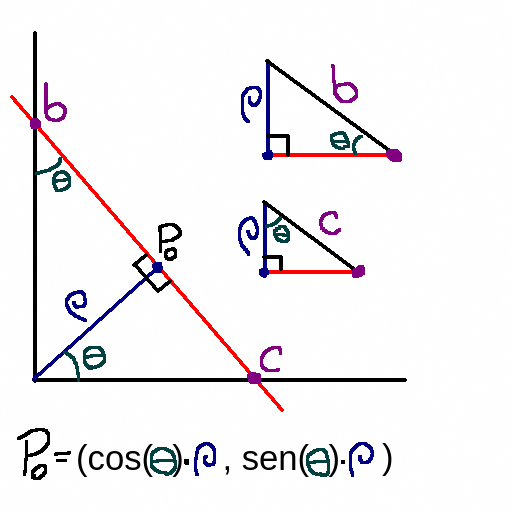

LLamemos $P_0$ al punto de $f$ mas cercano al $(0,0)$, es decir, es la interseccion con una linea perpendicular que pasa por el origen.

Sean $\textbf{θ}$ y $\textbf{ρ}$ las coordenadas polares de $P_0$. Veamos que podremos reescribir $\textbf{b}$ y $\textbf{c}$ (interseccion con el eje $x$) en funcion de $θ$ y $ρ$

$$b= \frac{ρ}{sen(\theta)}$$

$$c= \frac{ρ}{cos(\theta)}$$

Con esto tambien podremos definir $\textbf{m}$

$$m= \frac{Δx}{Δy} = \frac{f(c)-f(0)}{c} = \frac{-b}{c} = -\frac{cos(\theta)}{sen(\theta)}$$


Entonces, podemos reescribir $f$ como

$$y = -x\cdot\frac{cos(\theta)}{sen(\theta)} + \frac{ρ}{sen(\theta)}$$

La cual es una representacion de $f$ que esta definida con $\textbf{θ}$ y $\textbf{ρ}$. De esta forma, sabremos que $f$ sera vertical cuando $\textbf{sen(θ) = 0}$


In [ ]:
#@title Recta en el plano cartesiano y en el espacio ρ-θ { display-mode: "form" }

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

def graficar(theta=45, rho=50):
    rad_theta = np.radians(theta)
    cos_theta, sin_theta = np.cos(rad_theta), np.sin(rad_theta)
    x0, y0 = rho * cos_theta, rho * sin_theta

    fig, axs = plt.subplots(1, 2, figsize=(10, 5))

    # Plano cartesiano
    # La recta es vertical cuando sin(theta) = 0 (theta = 0, 180, 360)
    if np.isclose(sin_theta, 0):
        axs[0].axvline(x=x0, color='r')
    else:
        axs[0].axline((x0, y0), slope=-cos_theta / sin_theta, color='r')

    axs[0].plot([0, x0], [0, y0], marker='o', linestyle='--')
    axs[0].set_xlim(-200, 200)
    axs[0].set_ylim(-200, 200)
    axs[0].grid(True)
    axs[0].set_xlabel('x')
    axs[0].set_ylabel('y')
    axs[0].set_title(f'Plano Cartesiano | Línea (θ = {theta}°, ρ = {rho})')

    # Plano rho-theta
    axs[1].plot([theta], [rho], marker='o', color='r')
    axs[1].set_xlim(0, 360)
    axs[1].set_ylim(-200, 200)
    axs[1].grid(True)
    axs[1].set_xlabel('θ')
    axs[1].set_ylabel('ρ')
    axs[1].set_title('Proyección ρ θ')

    plt.tight_layout()
    plt.show()

estilo_slider = {'description_width': 'initial'}
interact(
    graficar,
    theta=widgets.IntSlider(value=45, min=0, max=360, step=1, description='θ (grados)',
                            continuous_update=True, style=estilo_slider),
    rho=widgets.IntSlider(value=50, min=-200, max=200, step=1, description='ρ',
                          continuous_update=True, style=estilo_slider),
);

De la misma forma que una *linea* del **plano cartesiano** puede representarse en el **plano** $\textbf{ρ}$ $\textbf{θ}$ como un *punto*, podremos representar un *punto* del **plano cartesiano** en el **plano** $\textbf{ρ}$ $\textbf{θ}$ como el *conjunto* de todas las lineas a las que podria formar parte.

Para esto usaremos que vale
$$\rho = x⋅cos(\theta) + y⋅cos(\theta)$$
para cada punto $(x,y)$ que pertence a la linea $(\theta,\rho)$

In [ ]:
#@title Transformada de Hough: un punto → curva en ρ-θ { display-mode: "form" }
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

def graficar(x_punto=100, y_punto=50, paso=10):
    # Solo hasta 180°, ya que más allá se repiten las líneas con ρ negativo
    thetas = np.arange(0, 181, paso)
    rad_thetas = np.radians(thetas)
    rhos = x_punto * np.cos(rad_thetas) + y_punto * np.sin(rad_thetas)

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))

    # Punto
    axs[0].plot([x_punto], [y_punto], marker='o', color='r')
    axs[0].set_xlim(-200, 200)
    axs[0].set_ylim(-200, 200)
    axs[0].grid(True)
    axs[0].set_xlabel('x')
    axs[0].set_ylabel('y')
    axs[0].set_title(f'Punto (x={x_punto}, y={y_punto})')

    # Plano rho-theta
    axs[1].plot(thetas, rhos, marker='o')
    axs[1].set_xlim(0, 180)
    axs[1].set_ylim(-200, 200)
    axs[1].grid(True)
    axs[1].set_xlabel('θ')
    axs[1].set_ylabel('ρ')
    axs[1].set_title('Posibles líneas ρ θ')

    # Líneas posibles en el plano cartesiano
    for rad_theta, rho in zip(rad_thetas, rhos):
        cos_theta, sin_theta = np.cos(rad_theta), np.sin(rad_theta)
        x0, y0 = cos_theta * rho, sin_theta * rho
        if np.isclose(sin_theta, 0):  # vertical (θ = 0° o 180°)
            axs[2].axvline(x=x0)
        else:
            axs[2].axline((x0, y0), slope=-cos_theta / sin_theta)

    axs[2].plot([x_punto], [y_punto], marker='o', color='r')
    axs[2].set_xlim(-200, 200)
    axs[2].set_ylim(-200, 200)
    axs[2].grid(True)
    axs[2].set_xlabel('x')
    axs[2].set_ylabel('y')
    axs[2].set_title('Líneas en el plano cartesiano')

    plt.tight_layout()
    plt.show()

estilo_slider = {'description_width': 'initial'}
interact(
    graficar,
    x_punto=widgets.IntSlider(value=100, min=-200, max=200, step=1, description='x', style=estilo_slider),
    y_punto=widgets.IntSlider(value=50, min=-200, max=200, step=1, description='y', style=estilo_slider),
    paso=widgets.IntSlider(value=10, min=1, max=45, step=1, description='paso θ (°)', style=estilo_slider),
);

Todos los puntos que pertenecen a una misma recta, tendran una interseccion en el **plano** $\textbf{ρ}$ $\textbf{θ}$ cuyas coordenadas seran los parametros que definiran la linea a la que pertenecen.

In [ ]:
#@title Puntos sobre una recta → curvas en ρ-θ que se cruzan en (θ, ρ) de la recta { display-mode: "form" }
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

def graficar(theta=90, rho=50):
    rad_theta = np.radians(theta)
    cos_theta, sin_theta = np.cos(rad_theta), np.sin(rad_theta)

    # Punto de la recta más cercano al origen y dirección de la recta
    x0, y0 = rho * cos_theta, rho * sin_theta
    direccion = np.array([-sin_theta, cos_theta])

    # 3 puntos sobre la recta (posición t a lo largo de ella)
    ts = np.array([100, 0, -100])
    puntos = np.array([x0, y0]) + np.outer(ts, direccion)
    colores = ['r', 'g', 'b']

    # Curvas ρ(θ) de cada punto
    thetas = np.linspace(0, 180, 361)
    rad_thetas = np.radians(thetas)
    rhos = np.outer(puntos[:, 0], np.cos(rad_thetas)) + np.outer(puntos[:, 1], np.sin(rad_thetas))

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))

    # Puntos
    for (x, y), color_punto in zip(puntos, colores):
        axs[0].plot(x, y, marker='o', color=color_punto)
    axs[0].set_title('Puntos')

    # Plano ρ-θ
    for rhos_punto, color_punto in zip(rhos, colores):
        axs[1].plot(thetas, rhos_punto, color=color_punto)
    axs[1].plot(theta, rho, marker='s', markersize=6, color='m')
    axs[1].set_xlim(0, 180)
    axs[1].set_xlabel('θ')
    axs[1].set_ylabel('ρ')
    axs[1].set_title(f'Curvas ρ θ | intersección (θ={theta}°, ρ={rho})')

    # Recta en el plano cartesiano
    for (x, y), color_punto in zip(puntos, colores):
        axs[2].plot(x, y, marker='o', color=color_punto)
    if np.isclose(sin_theta, 0):  # vertical (θ = 0° o 180°)
        axs[2].axvline(x0, color='m')
    else:
        axs[2].axline((x0, y0), slope=-cos_theta / sin_theta, color='m')
    axs[2].set_title('Recta en el plano cartesiano')

    for i, ax in enumerate(axs):
        ax.set_ylim(-200, 200)
        ax.grid(True)
        if i != 1:
            ax.set_xlim(-200, 200)
            ax.set_xlabel('x')
            ax.set_ylabel('y')

    plt.tight_layout()
    plt.show()

estilo_slider = {'description_width': 'initial'}
interact(
    graficar,
    theta=widgets.IntSlider(value=90, min=0, max=180, step=1, description='θ (grados)', style=estilo_slider),
    rho=widgets.IntSlider(value=50, min=-200, max=200, step=1, description='ρ', style=estilo_slider),
);

Utilizando esta propiedad, pordremos utilizar la transformada de Hough para detectar lineas. La idea consistira en pasar por cada punto de la imagen, calcular cada una de sus posibles lineas y luego quedarnos con las lineas de mayor numero de 'votos'.

Como hay infinitas lineas por cada punto, tendremos que discretizar el plano rho, theta en bins.

### ***Ejercicio***: Implementar el Detector de Lineas con Transformada de Hough

Dada una imagen ya binarizada, devolver todos los pares *(rho, theta)* que tengan al menos **75%** de los votos que el participante con mayor votos y *sobrevivan* a la *supresion de no maximo*. **El resultado debe ser una matriz, donde la primera columna sera rho y la segunda theta.**

- Ejercicio: implementar utilizando loops y procesando UN voto a la vez:
    - aplicar_voto
    - supresion_no_maximo
    - extraer_lineas
    - transformada_hough
  
- Ejercicio Opcional: reescribir lo mismo de forma vectorizada, calculando de forma todos los rhos de cada punto y aplicando todos los votos a la vez.
    - aplicar_votos_vectorizado
    - transformada_hough_vectorizada


In [ ]:
# Dado un theta en radianes, un rho, ax y un color, plotea en ax la linea descrita por rho y theta
def plot_hough_line(rho, theta, ax, color):
  print()
  cos_theta = np.cos(theta)
  sin_theta = np.sin(theta)

  x0 = cos_theta * rho
  y0 = sin_theta * rho

  # Verificamos que la linea no sea vertical
  # Si no lo es, calculamos su pendiente
  if np.isclose(theta, 0):
      pendiente = np.inf  # vertical line
  else:
      pendiente = -cos_theta / sin_theta

  if np.isinf(pendiente):
      # linea vertical
      ax.axvline(x=x0, color=color)
  else:
      ax.axline((x0, y0), slope=pendiente, color=color)

In [ ]:
def inicializar_matriz_votos_lineas(imagen, theta_bins= 180, rho_bins=100):
  # theta en [-pi/2, pi/2) y rho en [-diagonal_imagen, diagonal_imagen]
  thetas, theta_step = np.linspace(-np.pi/2, np.pi/2, theta_bins, endpoint=False, retstep=True)
  diagonal_imagen = int(np.ceil(np.sqrt(imagen.shape[0] * imagen.shape[0] + imagen.shape[1] * imagen.shape[1])))
  rhos, rho_step = np.linspace(-diagonal_imagen, diagonal_imagen, rho_bins, endpoint=True, retstep=True)

  accum = np.zeros((rhos.shape[0], thetas.shape[0]), dtype=np.float64)

  return accum, (thetas, theta_step), (rhos, rho_step)

In [ ]:
def conseguir_puntos_de_imagen_binarizada(imagen):
  puntos_y, puntos_x = np.where(imagen != 0)
  return puntos_x, puntos_y

In [ ]:
import numpy as np
from scipy.ndimage import maximum_filter

def wrappear_thetas(matriz, longitud_wrap):
  # Como theta es periodica, vamos a hacer un wrap para tomar en cuenta los valores que geometricamente estan cercanos
  # pero son lejanos en la matriz
  # para esto pegamos en la matriz las ultimas columnas en el orden inverso primero y luego las primeras columnas las pegamos a lo ultimo
  # matriz[::-1, -longitud_wrap:] -> ultimas columnas orden inverso de columan, orden inverso de fila
  # matriz[::-1, :longitud_wrap] -> primeras columans orden normal de columna, orden inverso de fila
  # np.hstack -> concatena por columna
  return np.hstack((matriz[::-1, -longitud_wrap:], matriz, matriz[::-1, :longitud_wrap])) if longitud_wrap > 0 else matriz

def supresion_no_maximo(matriz, vecindad_supresion_no_maximo):

  # Modifica directamente a la matriz pasada
  # Debe devolver una matriz unicamente con los maximos y el resto de valores en 0
  # Para hacerlo rapido vamos a utilizar un filtro maximo
  size = (vecindad_supresion_no_maximo, vecindad_supresion_no_maximo)

  # theta es periodico: (theta + pi, rho) es la misma recta que (theta, -rho).
  # Entonces, pasado el borde de theta, la vecindad continua del otro lado con rho invertido.
  k = vecindad_supresion_no_maximo // 2
  extendida = wrappear_thetas(matriz, k)

  #aplica un filtro de maximo sobre la imagen
  res_kernel_max = maximum_filter(extendida, size=size, mode="constant", cval=0)
  # Eliminamos las columnas extendidas y volvemos a la matriz original
  res_kernel_max = res_kernel_max[:, k:k + matriz.shape[1]]

  # Como podemos usar el resultado de res_kernel_max para hacer supresion de no maximo?.
  # Completar


In [ ]:
def extraer_lineas(accum, thetas, rhos, vecindad_supresion_no_maximo):
  # Pasos que van a compartir las dos implementaciones
  # Realiza la supresion de no maximo y aplica el umbral del %75, devuelve la matriz con una columna de rhos y otra de thetas.
  supresion_no_maximo(accum, vecindad_supresion_no_maximo)

  # Nos quedamos con los bins que tengan al menos el 75% del maximo global
  # COMPLETAR
  # conseguir_puntos_de_imagen_binarizada devuelve (columnas, filas) = ??
  # COMPLETAR

  # Primera columna rho, segunda thetas
  # El 1 que esta puesto no tiene sentido, es solo para devolver algo hasta que completen la implementacion.
  return np.column_stack((rhos[1], thetas[1]))

#### Con loops

Primero un voto individual: dado un `theta` y un `rho` (escalares), sumamos al acumulador con interpolacion lineal entre los dos bins de rho mas cercanos.

In [ ]:
def aplicar_voto(accum, theta, theta_step, rho, rho_step):

  # Aplica UN voto. theta y rho son numeros
  # Recuerden que tienen que aplicar interpolacion lineal entre los bines de rho
  # Modifica directamente a la matriz accum.

  # accum tiene forma (rho_bins, theta_bins)
  numero_rhos, numero_thetas = accum.shape

  # Los rangos son simetricos: theta en [-pi/2, pi/2) y rho en [-rho_max, rho_max]
  theta_min = -(numero_thetas * theta_step) / 2
  # es menos uno porque el maximo forma parte
  rho_min = -(numero_rhos - 1) * rho_step / 2

  # bin de theta, no realizamos interpolacion
  theta_idx = int(np.round((theta - theta_min) / theta_step))

  # Rho: interpolación lineal entre los dos bins vecinos
  rho_idx_entre_bines = (rho - rho_min) / rho_step
  rho_idx = int(np.floor(rho_idx_entre_bines))
  porcentaje_por_afuera = rho_idx_entre_bines - rho_idx

  # Ignoramos los votos que caen fuera del acumulador
  # Completar

  # Bin inferior recibe (1 - porcentaje), bin superior recibe porcentaje
  # Completar

In [ ]:
def transformada_hough(imagen, theta_bins = 360, rho_bins= 201, vecindad_supresion_no_maximo=9):
  # Creamos un acumulador con los posibles thetas y rhos
  accum, (thetas, theta_step), (rhos, rho_step) = inicializar_matriz_votos_lineas(imagen, theta_bins, rho_bins)
  puntos_x, puntos_y = conseguir_puntos_de_imagen_binarizada(imagen)

  # Por cada punto calculamos su rho para cada theta y votamos
  for x, y in zip(puntos_x, puntos_y):
    # Completar
    pass

  return extraer_lineas(accum, thetas, rhos, vecindad_supresion_no_maximo)

### Imagenes

In [ ]:
from skimage import data, util, color
from skimage.feature import canny

def cargar_imagen_cohete():
  imagen_gris = util.img_as_float32(color.rgb2gray(data.rocket()))[:200, 0:200]
  return imagen_gris, canny(imagen_gris)

def crear_imagen_desde_puntos(puntos):  # puntos como (fila, columna)
  imagen = np.zeros((100, 100))
  for fila, columna in puntos:
    imagen[fila][columna] = 1
  return imagen

def plot_hough_lines(imagen, titulo, parametros_lineas, imagen_original_gris = None):

  numero_ax = 2 if imagen_original_gris is None else 3
  tamanio_horizontal = 10 if imagen_original_gris is None else 15
  idx_imagen_binarizada = 0 if imagen_original_gris is None else 1

  fig, axs = plt.subplots(1, numero_ax, figsize=(tamanio_horizontal, 5))

  if imagen_original_gris is not None:
    axs[0].imshow(imagen_original_gris, cmap='gray')
    axs[0].set_title(f'Imagen Original')
    axs[0].axis(False)

  axs[idx_imagen_binarizada].imshow(imagen, cmap='gray')
  axs[idx_imagen_binarizada].set_title(f'{titulo}')
  axs[idx_imagen_binarizada].axis(False)

  axs[idx_imagen_binarizada + 1].imshow(imagen, cmap='gray')
  axs[idx_imagen_binarizada + 1].set_title(f'{titulo} Hough')
  axs[idx_imagen_binarizada + 1].set_xlim(0, imagen.shape[1] - 1)
  axs[idx_imagen_binarizada + 1].set_ylim(imagen.shape[0] - 1, 0)
  axs[idx_imagen_binarizada + 1].axis(False)

  for i in range(parametros_lineas.shape[0]):
    plot_hough_line(parametros_lineas[i][0], parametros_lineas[i][1], axs[idx_imagen_binarizada + 1], 'r')

  plt.tight_layout()
  plt.show()

imagen_vertical = crear_imagen_desde_puntos([(20, 50), (40, 50), (70, 50)])
imagen_horizontal = crear_imagen_desde_puntos([(50, 20), (50, 40), (50, 70)])
imagen_mix = crear_imagen_desde_puntos([(20, 40), (30, 60), (40, 80), (40, 20), (60, 30), (80, 40), (20, 20), (30, 30), (40, 40)])
imagen_cohete_gris, imagen_cohete_bordes = cargar_imagen_cohete()

### Tests

In [ ]:
THETA_BINS = 360
RHO_BINS = 201
VECINDAD = 9

In [ ]:
import time

IMAGENES_DE_TEST = {
    'vertical': imagen_vertical,
    'horizontal': imagen_horizontal,
    'mix': imagen_mix,
    'cohete': imagen_cohete_bordes,
  }

# Lineas esperadas [rho, theta en grados] con los bins de arriba
LINEAS_ESPERADAS = {
  'vertical':   [[49.7, -0.5]],
  'horizontal': [[-49.7, -89.5]],
  'mix':        [[-39.76, -89.5], [0.0, -63.5], [0.0, -45.0], [0.0, -26.5], [39.76, -0.5], [42.6, 45.0]],
  'cohete':     [[56.6, 7.5], [87.73, 2.0]],
}

def verificar(nombre, implementacion_hough, implementacion_titulo):
  imagen = IMAGENES_DE_TEST[nombre]
  esperadas = np.array(LINEAS_ESPERADAS[nombre])
  inicio = time.perf_counter()
  lineas = implementacion_hough(imagen, THETA_BINS, RHO_BINS, VECINDAD)
  tiempo = time.perf_counter() - inicio

  obtenidas = np.column_stack((lineas[:, 0], np.degrees(lineas[:, 1])))
  assert obtenidas.shape == esperadas.shape and np.allclose(obtenidas, esperadas, atol=0.01), \
      f"[{implementacion_titulo}] se esperaba {esperadas.tolist()} pero se obtuvo {np.round(obtenidas, 2).tolist()}"
  print(f"OK [{implementacion_titulo}] {nombre}: {tiempo * 1000:.1f} ms")

### Verificacion Loop

In [ ]:
parametros_lineas = transformada_hough(imagen_vertical, THETA_BINS, RHO_BINS, VECINDAD)
plot_hough_lines(imagen_vertical, "Lineas Verticales", parametros_lineas)

In [ ]:
verificar('vertical', transformada_hough, "loop")

In [ ]:
parametros_lineas = transformada_hough(imagen_horizontal, THETA_BINS, RHO_BINS, VECINDAD)
plot_hough_lines(imagen_horizontal, "Lineas Horizontales", parametros_lineas)

In [ ]:
verificar('horizontal', transformada_hough, "loop")

In [ ]:
parametros_lineas = transformada_hough(imagen_mix, THETA_BINS, RHO_BINS, VECINDAD)
plot_hough_lines(imagen_mix, "Lineas Mix", parametros_lineas)

In [ ]:
verificar('mix', transformada_hough, "loop")

In [ ]:
# Abrimos una imagen y encontramos sus bordes con Canny
parametros_lineas = transformada_hough(imagen_cohete_bordes, THETA_BINS, RHO_BINS, VECINDAD)
plot_hough_lines(imagen_cohete_bordes, "Lineas Cohete", parametros_lineas, imagen_original_gris=imagen_cohete_gris)

In [ ]:
verificar('cohete', transformada_hough, "loop")

#### Opcional: Vectorizado

Ahora lo mismo sin loops. Deberiamos calcular todos los rho de una vez y aplicar el voto todos juntos.

Usen `np.add.at` para agregar, ya que habra indices repetidos. Combiene utilizar dos arrays largos para que sea lo mas rapido posible, en vez de una matriz. Si alguno quiere puede implementarlo en assembly con instrucciones de SIMD (extra opcional).

In [ ]:
def aplicar_votos_vectorizado(accum, thetas, theta_step, rhos, rho_step):

  # Se espera que rhos y thetas sean vectores, cada theta y rho es un voto.
  # accum tiene forma (rho_bins, theta_bins)
  numero_rhos, numero_thetas = accum.shape

  # Los rangos son simetricos: theta en [-pi/2, pi/2) y rho en [-rho_max, rho_max]
  theta_min = -numero_thetas * theta_step / 2
  # El maximo esta, asi que restamos uno
  rho_min = -(numero_rhos - 1) * rho_step / 2

  # bin de thetas
  theta_idxs = np.round((thetas - theta_min) / theta_step).astype(int)

  # Rho: interpolación lineal entre los dos bins vecinos
  rho_idxs_entre_bines = (rhos - rho_min) / rho_step
  rho_idxs = np.floor(rho_idxs_entre_bines).astype(int)
  porcentaje_por_afuera = rho_idxs_entre_bines - rho_idxs

  # Bin inferior recibe (1 - porcentaje), bin superior recibe porcentaje
  # Primero actualizamos el rho_idxs, luego el bin siguiente (rho_idxs + 1) por el resto
  # Van a necesitar la funcion np.add.at
  # Pueden usar una mascara booleana para indexar en np.add.at, asi verifican los votos validos.
  # Completar

In [ ]:
def transformada_hough_vectorizada(imagen, theta_bins = 360, rho_bins= 201, vecindad_supresion_no_maximo=9):

  accum, (thetas, theta_step), (rhos, rho_step) = inicializar_matriz_votos_lineas(imagen, theta_bins, rho_bins)
  puntos_x, puntos_y = conseguir_puntos_de_imagen_binarizada(imagen)

  # rho de cada punto para cada theta, forma (n_puntos, theta_bins)
  # Les combiene jugar con np.outer para hacer todos los calculos de una.
  # Despues pueden usar ravel para volverlo flat
  # Completar

  # Vean que los theta van a ser los mismos por cada rho, por lo pueden usar np.tile.
  # Completar

  # Llamar a aplicar votos vectorizado
  aplicar_votos_vectorizado(accum, COMPLETAR, theta_step, COMPLETAR, rho_step)

  # Extraer lineas
  return extraer_lineas(accum, thetas, rhos, vecindad_supresion_no_maximo)

### Verificacion Vectorizado

In [ ]:
parametros_lineas = transformada_hough_vectorizada(imagen_vertical, THETA_BINS, RHO_BINS, VECINDAD)
plot_hough_lines(imagen_vertical, "Lineas Verticales", parametros_lineas)

In [ ]:
verificar('vertical', transformada_hough_vectorizada, "vectorizada")

In [ ]:
parametros_lineas = transformada_hough_vectorizada(imagen_horizontal, THETA_BINS, RHO_BINS, VECINDAD)
plot_hough_lines(imagen_horizontal, "Lineas Horizontales", parametros_lineas)

In [ ]:
verificar('horizontal', transformada_hough_vectorizada, "vectorizada")

In [ ]:
parametros_lineas = transformada_hough_vectorizada(imagen_mix, THETA_BINS, RHO_BINS, VECINDAD)
plot_hough_lines(imagen_mix, "Lineas Mix", parametros_lineas)

In [ ]:
verificar('mix', transformada_hough_vectorizada, "vectorizada")

In [ ]:
# Abrimos una imagen y encontramos sus bordes con Canny
parametros_lineas = transformada_hough_vectorizada(imagen_cohete_bordes, THETA_BINS, RHO_BINS, VECINDAD)
plot_hough_lines(imagen_cohete_bordes, "Lineas Cohete", parametros_lineas, imagen_original_gris=imagen_cohete_gris)

In [ ]:
verificar('cohete', transformada_hough_vectorizada, "vectorizada")

## **Transformada de Hough para Circulos**

Un circulo esta definido por su ***centro*** $(a, b)$ y su ***radio*** ($r$). Todos los puntos $(x, y)$ del circulo cumplen

$$(x - a)^2 + (y - b)^2 = r^2$$

o, escrito con un angulo $\textbf{θ}$,

$$x = a + r\cdot cos(\theta) \qquad y = b + r\cdot sen(\theta)$$

Siguiendo esta definicion podemos implementar un algoritmo similar a la transformada de Hough para lineas. En este caso tendriamos 3 incognitas en vez de 2, $a$, $b$ y $r$, Para simplificar computacionalmente el problema vamos a suponer que el radio ($r$) es conocido, por lo que solo debemos encontrar el centro $(a, b)$.

![Descripcion de la imagen](https://miro.medium.com/v2/resize:fit:1200/1*JxcdqbqV8p4zjQDN5qWbiQ.png)

De la misma forma que un *punto* se representaba en el plano $\textbf{ρ}$ $\textbf{θ}$ como el conjunto de lineas a las que podia formar parte, un *punto* $(x, y)$ del borde de un circulo de radio $r$ se representara en el plano $\textbf{a}$ $\textbf{b}$ como el conjunto de circulos a los que podria pertenecer. Un punto $(x, y)$ puede venir de cualquier circulo con distancia $r$ de su centro. Despejando de lo anterior, los centros posibles son

$$a = x - r\cdot cos(\theta) \qquad b = y - r\cdot sen(\theta) \qquad \theta \in [0, 2\pi)$$

Al igual manera que cuando descubriamos las lineas, todos los puntos que pertenecen a un mismo circulo de radio $r$ tendran una interseccion en el plano $\textbf{a}$ $\textbf{b}$. Esta interseccion sera el **centro real** del circulo.

![Descripcion de la imagen](https://miro.medium.com/1*x5HyOssypWmI8Qklwcs66g.png)

In [ ]:
#@title Puntos sobre un circulo → circulos de centros posibles que se cruzan en el centro { display-mode: "form" }
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

def graficar(centro_x=0, centro_y=0, radio=60):
    # 3 puntos sobre el circulo
    thetas = np.radians([30, 150, 270])
    puntos_x = centro_x + radio * np.cos(thetas)
    puntos_y = centro_y + radio * np.sin(thetas)
    colores = ['r', 'g', 'b']

    fig, ax = plt.subplots(figsize=(6, 6))

    # Circulo original
    ax.add_patch(plt.Circle((centro_x, centro_y), radio, fill=False, color='k'))

    # Puntos y sus circulos de centros posibles
    for x, y, color_punto in zip(puntos_x, puntos_y, colores):
        ax.plot(x, y, marker='o', color=color_punto)
        ax.add_patch(plt.Circle((x, y), radio, fill=False, linestyle='--', color=color_punto))

    # Interseccion: el centro del circulo
    ax.plot(centro_x, centro_y, marker='s', markersize=7, color='m')

    ax.set_xlim(-200, 200)
    ax.set_ylim(-200, 200)
    ax.set_aspect('equal')
    ax.grid(True)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(f'Circulo (a={centro_x}, b={centro_y}, r={radio}) y centros posibles de cada punto')

    plt.tight_layout()
    plt.show()

estilo_slider = {'description_width': 'initial'}
interact(
    graficar,
    centro_x=widgets.IntSlider(value=0, min=-100, max=100, step=1, description='a (centro x)', style=estilo_slider),
    centro_y=widgets.IntSlider(value=0, min=-100, max=100, step=1, description='b (centro y)', style=estilo_slider),
    radio=widgets.IntSlider(value=60, min=10, max=100, step=1, description='r (radio)', style=estilo_slider),
);

### ***Ejercicio***: Implementar el Detector de Circulos con Transformada de Hough

Dada una imagen ya binarizada y el radio $r$ de los circulos a buscar, devolver todos los centros $(a, b)$ que tengan al menos **75%** de los votos del centro con mayor votos y *sobrevivan* a la *supresion de no maximo*. **El resultado debe ser una matriz, donde la primera columna sera la coordenada x del centro ($a$) y la segunda la coordenada y ($b$).**

Hay dos diferencias con las lineas:

- El acumulador tiene el mismo tamaño que la imagen: cada bin es un posible centro. $θ$ ya no es una dimension del acumulador, solo se usa para recorrer los centros posibles de cada punto.
- Como $θ$ no es una dimension, no hay que hacer el wrap de la supresion de no maximo de lineas.

Igual que antes, el ejercicio es con loops y el ejercicio opcional es la version vectorizada. Los votos se reparten con interpolacion bilineal entre los 4 bins vecinos del centro.

Opcionalmente se puede pasar `votos_minimos`: la cantidad minima de votos que tiene que tener un centro para contar. Si se pasa, reemplaza al 75% del maximo. Lo vamos a utilizar cuando una imagen puede no contener ningun circulo.

- Ejercicio: implementar utilizando loops y procesando UN voto a la vez:
    - aplicar_voto_circulo
    - supresion_no_maximo_circulos
    - extraer_circulos
    - transformada_hough_circulos
  
- Ejercicio Opcional: reescribir lo mismo de forma vectorizada, calculando de forma todos los rhos de cada punto y aplicando todos los votos a la vez.
    - aplicar_votos_circulo_vectorizado
    - transformada_hough_circulos_vectorizada

In [ ]:
from scipy.ndimage import maximum_filter

def inicializar_matriz_votos_circulos(imagen, theta_bins=180):
  # Un bin por pixel: cada bin es un posible centro (accum[y, x])
  thetas = np.linspace(0, 2*np.pi, theta_bins, endpoint=False)
  accum = np.zeros(imagen.shape, dtype=np.float64)
  return accum, thetas

def supresion_no_maximo_circulos(matriz, vecindad_supresion_no_maximo):
  size = (vecindad_supresion_no_maximo, vecindad_supresion_no_maximo)
  # Aplicamos filtro de maximo
  res_kernel_max = maximum_filter(matriz, size=size, mode="constant", cval=0)
  # Los bins que no son maximo local pasan a 0 (modificamos matriz directamente)
  # Como pueden hacer la supresion? Igual que antes
  # COMPLETAR

def extraer_circulos(accum, vecindad_supresion_no_maximo, votos_minimos=None):
  # Pasos que van a compartir las dos implementaciones
  # Realiza la supresion de no maximo y aplica el umbral del %75 o el de votos minimos, devuelve la matriz con una columna de as y otra de bs.
  supresion_no_maximo_circulos(accum, vecindad_supresion_no_maximo)

  # Nos quedamos con los bins que tengan al menos el 75% del maximo global,
  # o al menos votos_minimos si se pasa
  # COMPLETAR
  # conseguir_puntos_de_imagen_binarizada devuelve (columnas, filas) = ???
  # COMPLETAR

  # Primera columna x del centro, segunda y del centro
  # Los valores actuales son solo un template.
  return np.column_stack(([1], [1]))

#### Con loops

Primero un voto individual: dado un centro posible $(a, b)$ (escalares, puede caer entre pixeles), sumamos al acumulador repartiendo el voto entre los 4 bins vecinos segun que tan cerca esta cada uno.

Parecido a lo que ya hicieron para rho, pero en ambas direcciones.

In [ ]:
def aplicar_voto_circulo(accum, centro_x, centro_y):
  # Aplica UN voto. centro_x y centro_y son escalares
  # Apliquen la interpolacion de a y b
  # accum tiene forma (alto, ancho) y se indexa accum[y, x]
  alto, ancho = accum.shape

  # Calculamos los indices de los centros y su resto entre bines
  # Cada pixel es un bin
  x0 = int(np.floor(centro_x))
  y0 = int(np.floor(centro_y))
  porcentaje_x = centro_x - x0
  porcentaje_y = centro_y - y0

  # Cada bin vecino recibe un peso proporcional a su cercania al centro calculado.
  # Combiene tratar cada cuadrante por separado.
  # Completar

In [ ]:
def transformada_hough_circulos(imagen, radio, theta_bins=180, vecindad_supresion_no_maximo=9, votos_minimos=None):
  # Creamos el acumulador
  accum, thetas = inicializar_matriz_votos_circulos(imagen, theta_bins)
  # Encontramos los puntos para detectar un circulo
  puntos_x, puntos_y = conseguir_puntos_de_imagen_binarizada(imagen)

  # Por cada punto calculamos cada centro posible y votamos
  for x, y in zip(puntos_x, puntos_y):
    #COMPLETAR
    pass

  # Una vez tenemos los votos, conseguimos los circulos
  return extraer_circulos(accum, vecindad_supresion_no_maximo, votos_minimos)

### Imagenes de circulos

In [ ]:
from skimage import io, color
from skimage.draw import circle_perimeter

def cargar_imagen_monedas(numero):
  imagen = io.imread(f'{CARPETA_IMAGENES}/monedas_{numero}.jpg')
  return imagen, canny(color.rgb2gray(imagen), sigma=2)

def crear_imagen_desde_circulos(circulos):  # circulos como (fila, columna, radio)
  imagen = np.zeros((100, 100))
  for fila, columna, radio in circulos:
    filas, columnas = circle_perimeter(fila, columna, radio, shape=imagen.shape)
    imagen[filas, columnas] = 1
  return imagen

def plot_hough_circle(centro_x, centro_y, radio, ax, color):
  ax.add_patch(plt.Circle((centro_x, centro_y), radio, fill=False, color=color, linewidth=2))
  ax.plot(centro_x, centro_y, marker='+', color=color)

def plot_hough_circles(imagen, titulo, parametros_circulos, radio, imagen_original = None):

  numero_ax = 2 if imagen_original is None else 3
  tamanio_horizontal = 10 if imagen_original is None else 15
  idx_imagen_binarizada = 0 if imagen_original is None else 1

  fig, axs = plt.subplots(1, numero_ax, figsize=(tamanio_horizontal, 5))

  if imagen_original is not None:
    axs[0].imshow(imagen_original, cmap='gray')
    axs[0].set_title(f'Imagen Original')
    axs[0].axis(False)

  axs[idx_imagen_binarizada].imshow(imagen, cmap='gray')
  axs[idx_imagen_binarizada].set_title(f'{titulo}')
  axs[idx_imagen_binarizada].axis(False)

  axs[idx_imagen_binarizada + 1].imshow(imagen, cmap='gray')
  axs[idx_imagen_binarizada + 1].set_title(f'{titulo} Hough')
  axs[idx_imagen_binarizada + 1].set_xlim(0, imagen.shape[1] - 1)
  axs[idx_imagen_binarizada + 1].set_ylim(imagen.shape[0] - 1, 0)
  axs[idx_imagen_binarizada + 1].axis(False)

  for i in range(parametros_circulos.shape[0]):
    plot_hough_circle(parametros_circulos[i][0], parametros_circulos[i][1], radio, axs[idx_imagen_binarizada + 1], 'r')

  plt.tight_layout()
  plt.show()

imagen_un_circulo = crear_imagen_desde_circulos([(50, 50, 20)])
# El tercer circulo tiene otro radio: no deberia ser detectado
imagen_circulos = crear_imagen_desde_circulos([(30, 30, 15), (65, 70, 15), (25, 70, 8)])
# Las 7 fotos de monedas (hay que subir la carpeta imagenes)
IMAGENES_MONEDAS = {numero: cargar_imagen_monedas(numero) for numero in range(1, 8)}
imagen_monedas_original, imagen_monedas_bordes = IMAGENES_MONEDAS[1]

### Tests de circulos

In [ ]:
THETA_BINS_CIRCULOS = 180

# Radio que se busca en cada imagen
RADIOS_CIRCULOS = {
    'un_circulo': 20,
    'circulos': 15,
    'monedas': 30,
  }

# Vecindad de la supresion de no maximos y votos minimos (None = 75% del maximo)
VECINDADES_CIRCULOS = {
    'un_circulo': 9,
    'circulos': 9,
    'monedas': 61,
  }

VOTOS_MINIMOS_CIRCULOS = {
    'un_circulo': None,
    'circulos': None,
    'monedas': 60,
  }

In [ ]:
IMAGENES_CIRCULOS = {
    'un_circulo': imagen_un_circulo,
    'circulos': imagen_circulos,
    'monedas': imagen_monedas_bordes,
  }

# Centros esperados [x, y] con los parametros de arriba
CIRCULOS_ESPERADOS = {
  'un_circulo': [[50, 50]],
  'circulos':   [[30, 30], [70, 65]],
  'monedas':    [[159, 102], [208, 177], [126, 212]],  # monedas_1.jpg: tres monedas de 1 peso
}

def verificar_circulos(nombre, implementacion_hough, implementacion_titulo):
  imagen = IMAGENES_CIRCULOS[nombre]
  esperados = np.array(CIRCULOS_ESPERADOS[nombre])
  inicio = time.perf_counter()
  obtenidos = implementacion_hough(imagen, RADIOS_CIRCULOS[nombre], THETA_BINS_CIRCULOS, VECINDADES_CIRCULOS[nombre], VOTOS_MINIMOS_CIRCULOS[nombre])
  tiempo = time.perf_counter() - inicio

  assert obtenidos.shape == esperados.shape and np.allclose(obtenidos, esperados, atol=0.01), \
      f"[{implementacion_titulo}] se esperaba {esperados.tolist()} pero se obtuvo {obtenidos.tolist()}"
  print(f"OK [{implementacion_titulo}] {nombre}: {tiempo * 1000:.1f} ms")

### Verificacion Loops (Circulos)

In [ ]:
parametros_circulos = transformada_hough_circulos(imagen_un_circulo, RADIOS_CIRCULOS['un_circulo'], THETA_BINS_CIRCULOS, VECINDADES_CIRCULOS['un_circulo'], VOTOS_MINIMOS_CIRCULOS['un_circulo'])
plot_hough_circles(imagen_un_circulo, "Un Circulo", parametros_circulos, RADIOS_CIRCULOS['un_circulo'])

In [ ]:
verificar_circulos('un_circulo', transformada_hough_circulos, "loop")

In [ ]:
parametros_circulos = transformada_hough_circulos(imagen_circulos, RADIOS_CIRCULOS['circulos'], THETA_BINS_CIRCULOS, VECINDADES_CIRCULOS['circulos'], VOTOS_MINIMOS_CIRCULOS['circulos'])
plot_hough_circles(imagen_circulos, "Circulos", parametros_circulos, RADIOS_CIRCULOS['circulos'])

In [ ]:
verificar_circulos('circulos', transformada_hough_circulos, "loop")

In [ ]:
parametros_circulos = transformada_hough_circulos(imagen_monedas_bordes, RADIOS_CIRCULOS['monedas'], THETA_BINS_CIRCULOS, VECINDADES_CIRCULOS['monedas'], VOTOS_MINIMOS_CIRCULOS['monedas'])
plot_hough_circles(imagen_monedas_bordes, "Monedas", parametros_circulos, RADIOS_CIRCULOS['monedas'], imagen_original=imagen_monedas_original)

In [ ]:
verificar_circulos('monedas', transformada_hough_circulos, "loop")

#### Opcional: Vectorizado

Igual que con las lineas: calculamos todos los centros posibles de una vez y votamos todos juntos. `np.add.at` sigue siendo necesario porque hay indices repetidos.

In [ ]:
def aplicar_votos_circulo_vectorizado(accum, centros_x, centros_y):
  # Se espera que centros_x y centros_y sean np.ndarray de la misma longitud
  # accum tiene forma (alto, ancho) y se indexa accum[y, x]
  alto, ancho = accum.shape

  # Calculamos los indices de los centros y su resto entre bines
  # Cada pixel es un bin
  xs0 = np.floor(centros_x).astype(int)
  ys0 = np.floor(centros_y).astype(int)
  porcentajes_x = centros_x - xs0
  porcentajes_y = centros_y - ys0

  # Cada bin vecino recibe un peso proporcional a su cercania al centro
  # Combiene tratar cada cuadrante por separado
  # utilizen una mascara y np.add.at
  # Completar

In [ ]:
def transformada_hough_circulos_vectorizada(imagen, radio, theta_bins=180, vecindad_supresion_no_maximo=9, votos_minimos=None):
  accum, thetas = inicializar_matriz_votos_circulos(imagen, theta_bins)
  puntos_x, puntos_y = conseguir_puntos_de_imagen_binarizada(imagen)

  # Un centro posible por cada punto y cada theta, forma (n_puntos, theta_bins)
  # tiene que lograr hacer todas las operaciones de resta a la vez, luego puede convertirlo en un vector con ravel
  centros_x = #COMPLETAR
  centros_y = #COMPLETAR

  aplicar_votos_circulo_vectorizado(accum, centros_x, centros_y)

  return extraer_circulos(accum, vecindad_supresion_no_maximo, votos_minimos)

### Verificacion Vectorizado (circulos)

In [ ]:
parametros_circulos = transformada_hough_circulos_vectorizada(imagen_un_circulo, RADIOS_CIRCULOS['un_circulo'], THETA_BINS_CIRCULOS, VECINDADES_CIRCULOS['un_circulo'], VOTOS_MINIMOS_CIRCULOS['un_circulo'])
plot_hough_circles(imagen_un_circulo, "Un Circulo", parametros_circulos, RADIOS_CIRCULOS['un_circulo'])

In [ ]:
verificar_circulos('un_circulo', transformada_hough_circulos_vectorizada, "vectorizada")

In [ ]:
parametros_circulos = transformada_hough_circulos_vectorizada(imagen_circulos, RADIOS_CIRCULOS['circulos'], THETA_BINS_CIRCULOS, VECINDADES_CIRCULOS['circulos'], VOTOS_MINIMOS_CIRCULOS['circulos'])
plot_hough_circles(imagen_circulos, "Circulos", parametros_circulos, RADIOS_CIRCULOS['circulos'])

In [ ]:
verificar_circulos('circulos', transformada_hough_circulos_vectorizada, "vectorizada")

In [ ]:
parametros_circulos = transformada_hough_circulos_vectorizada(imagen_monedas_bordes, RADIOS_CIRCULOS['monedas'], THETA_BINS_CIRCULOS, VECINDADES_CIRCULOS['monedas'], VOTOS_MINIMOS_CIRCULOS['monedas'])
plot_hough_circles(imagen_monedas_bordes, "Monedas", parametros_circulos, RADIOS_CIRCULOS['monedas'], imagen_original=imagen_monedas_original)

In [ ]:
verificar_circulos('monedas', transformada_hough_circulos_vectorizada, "vectorizada")

In [ ]:
#@title Explorador de radios: jugar con las monedas { display-mode: "form" }
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

def explorar(numero_imagen=1, radio=30, votos_minimos=60):
  imagen_original, imagen_bordes = IMAGENES_MONEDAS[numero_imagen]
  circulos = transformada_hough_circulos_vectorizada(imagen_bordes, radio, THETA_BINS_CIRCULOS, 2 * radio + 1, votos_minimos)
  plot_hough_circles(imagen_bordes, f"Monedas {numero_imagen}", circulos, radio, imagen_original=imagen_original)
  print(f"Circulos de radio {radio} encontrados: {len(circulos)}")

interact(explorar,
         numero_imagen=widgets.IntSlider(min=1, max=7, step=1, value=1),
         radio=widgets.IntSlider(min=5, max=50, step=1, value=30),
         votos_minimos=widgets.IntSlider(min=0, max=150, step=1, value=60));

## **Ejercicio: Contador de pesos**

Un amigo tachero tiene una colección de monedas inmensa que fue recolectando a lo largo de los años cuando era común pagar con ellas. Cansado de que frascos enteros llenen su casa, decidió llevarlas al banco para depositarlas todas de una vez por todas. Pero antes de hacerlo le gustaría asegurarse que el costo de nafta de llevar las monedas a depositar no sea mayor al valor total de su colección. Para terminar con su duda te pidió ayuda a vos, sabiendo que tus habilidades en visión computacional eran más que suficientes para detectar monedas en una foto. Para hacer una prueba de concepto, tu amigo te mando unas fotos que muestran a unas cuantas monedas de su colección.

En las fotos hay tres tipos de monedas:

- 1 centavo (la mas chica)
- 1 peso (mediana)
- 2 pesos (la mas grande)

Como las fotos se sacaron siempre con la misma posicion, **cada tipo de moneda tiene siempre el mismo radio en pixeles**.

Usando los sliders de arriba, encuentren el radio de cada moneda y los `votos_minimos` que hacen falta para detectarla sin falsos positivos.

Ayudas:

- Una moneda grande tiene muchos mas puntos de borde que una chica, asi que necesita mas votos.
- Las monedas no se pueden superponer. Pueden usar esto para eliminar monedas de su busqueda de forma iterativa.

**Ejercicio**: Completen `MONEDAS`, encontrar_monedas y `contar_pesos`, que devuelve el **total en pesos** de las monedas de la imagen.

In [ ]:
# De la moneda mas grande a la mas chica. Completar con los radios y votos minimos que encontraron
MONEDAS = [
  {'nombre': 'dos pesos',  'radio': COMPLETAR, 'valor': 2.00, 'votos_minimos': COMPLETAR, 'color': 'r'},
  {'nombre': 'un peso',    'radio': COMPLETAR, 'valor': 1.00, 'votos_minimos': COMPLETAR, 'color': 'g'},
  {'nombre': 'un centavo', 'radio': COMPLETAR, 'valor': 0.01, 'votos_minimos': COMPLETAR, 'color': 'b'},
]

In [ ]:
def encontrar_monedas(imagen_bordes, implementacion_hough, monedas=MONEDAS):
  # les pasamos la funcion para que se pueda testear tanto en la version de loop como la vectorizada

  monedas_encontradas = []  # (x, y, radio, valor, color)

  for moneda in monedas:
    radio = moneda['radio']
    # Encuentren los circulos relacionado a los radios de cada moneda
    centros = # COMPLETAR

    for x, y in centros:

      # Van a tener que chequear si un circulo chico encontrado esta dentro de un circulo grande que ya habian encontrado antes
      # Vamos a suponer que las monedas nuncase tocan entre si, por lo que si esto sucede, descartamos al circulo mas chico
      # Dicho de otra forma, la distancia entre los centros siempre deberia ser mayor a la suma de los radios
      # De otra forma se estarian tocando.
      # Tenemos que hacer esto por cada uno de los circulos que conocemos,
      # Otra manera seria ir eliminando de forma iterativa los bordes de los circulos encontramos
      # Es eleccion de ustedes cual utilizar, la segunda es mas rapida.

      superpuesta = #COMPLETAR
      if not superpuesta:
        monedas_encontradas.append((x, y, radio, moneda['valor'], moneda['color']))

  return monedas_encontradas

def contar_pesos(imagen_bordes, implementacion_hough, monedas=MONEDAS):
  # Devuelve el total en pesos de las monedas que aparecen en la imagen, la imagen ya esta binarizada
  # COMPLETAR
  pass

### Imagenes de monedas

In [ ]:
def plot_monedas(numero, implementacion_hough, monedas=MONEDAS):
  imagen_original, imagen_bordes = IMAGENES_MONEDAS[numero]
  monedas_encontradas = encontrar_monedas(imagen_bordes, implementacion_hough, monedas)

  fig, axs = plt.subplots(1, 2, figsize=(10, 5))
  axs[0].imshow(imagen_original)
  axs[0].set_title('Imagen Original')
  axs[1].imshow(imagen_original)
  axs[1].set_title(f'Total: ${contar_pesos(imagen_bordes, implementacion_hough, monedas):.2f}')
  for x, y, radio, _, color in monedas_encontradas:
    plot_hough_circle(x, y, radio, axs[1], color)
  for ax in axs:
    ax.axis(False)
  plt.tight_layout()
  plt.show()

### Tests de monedas

In [ ]:
# Total esperado en pesos de cada foto
PESOS_ESPERADOS = {1: 3.00, 2: 4.00, 3: 4.01, 4: 4.01, 5: 5.00, 6: 3.01, 7: 3.01}

def verificar_pesos(numero, implementacion_hough, implementacion_titulo, monedas=MONEDAS):
  _, imagen_bordes = IMAGENES_MONEDAS[numero]
  inicio = time.perf_counter()
  obtenido = contar_pesos(imagen_bordes, implementacion_hough, monedas)
  tiempo = time.perf_counter() - inicio

  assert np.isclose(obtenido, PESOS_ESPERADOS[numero], atol=0.001), \
      f"[{implementacion_titulo}] monedas_{numero}: se esperaba ${PESOS_ESPERADOS[numero]} pero se obtuvo ${obtenido}"
  print(f"OK [{implementacion_titulo}] monedas_{numero}: ${obtenido:.2f} en {tiempo * 1000:.1f} ms")

### Verificacion contador (loop)

In [ ]:
for numero in IMAGENES_MONEDAS:
  plot_monedas(numero, transformada_hough_circulos)

In [ ]:
for numero in IMAGENES_MONEDAS:
  verificar_pesos(numero, transformada_hough_circulos, "loop")

### Verificacion contador (vectorizado)

In [ ]:
for numero in IMAGENES_MONEDAS:
  plot_monedas(numero, transformada_hough_circulos_vectorizada)

In [ ]:
for numero in IMAGENES_MONEDAS:
  verificar_pesos(numero, transformada_hough_circulos_vectorizada, "vectorizada")

## **(Opcional) Como usar informacion local para realizar menos votos**

Hasta ahora cada punto de borde votaba por todos los centros posibles, pero un punto de borde es tambien un pixel, por lo que podemos conseguir informacion de su **gradiente**.

$$\phi = arctan2(G_y, G_x)$$

En el borde de un circulo el gradiente es **perpendicular al borde**, es decir, que apunta en la direccion del radio. Esto nos da dos posible direcciones, una es hacia el centro y la direccion contraria. Ahora el angulo $\theta$ de los centros ya no es libre, sino que tiene que ser $\phi$ o $\phi + \pi$:

$$a = x \mp r\cdot cos(\phi) \qquad b = y \mp r\cdot sen(\phi)$$

![Descripcion de la imagen](https://www.researchgate.net/publication/348061374/figure/fig1/AS:11431281100658598@1669387123993/llustration-of-Gradient-Direction-used-in-Generalized-Hough-Transform-Reprinted-from.png)


Cada punto pasa de votar `theta_bins` centros a votar solo **2**. Usamos los dos porque el gradiente podria apunta hacia adentro o hacia afuera segun el contraste entre fondo y el circulo. Esto tiene dos ventajas:

- Es mucho mas rapido
- Hay menos ruido: los votos de los otros angulos solo sumaban votos en lugares donde no hay ningun centro.

El gradiente lo calculamos como siempre. Aplicamos un filtro gaussiando a una imagen de grises para suavizar el ruido y luego aplicamos Sobel.

Nota: Como cada punto vota menos veces, **los `votos_minimos` van a ser mas chicos** que antes.

- Ejercicio:
    - Implementar calcular_angulos_gradiente
    - transformada_hough_circulos_gradiente (version con loop)


In [ ]:
from skimage import filters

def calcular_angulos_gradiente(imagen_gris, sigma=3):
  # Angulo del gradiente en cada pixel, con la misma forma que la imagen
  # Aplicamos filtro gaussiano
  # Aplicamos sobel
  # Calculamos la arctan, y, x
  return 0

def plot_gradiente(imagen_original, imagen_bordes, angulos_gradiente, paso=6):
  puntos_x, puntos_y = conseguir_puntos_de_imagen_binarizada(imagen_bordes)
  puntos_x, puntos_y = puntos_x[::paso], puntos_y[::paso]
  angulos = angulos_gradiente[puntos_y, puntos_x]

  plt.figure(figsize=(5, 5))
  plt.imshow(imagen_original)
  plt.quiver(puntos_x, puntos_y, np.cos(angulos), -np.sin(angulos), color='r', angles='uv', scale=25, width=0.004)
  plt.title('Gradiente en los puntos de borde')
  plt.axis(False)
  plt.show()

In [ ]:
plot_gradiente(imagen_monedas_original, imagen_monedas_bordes, calcular_angulos_gradiente(color.rgb2gray(imagen_monedas_original)))

#### Hough con gradiente

Igual que `transformada_hough_circulos`, pero cada punto recibe tambien el angulo de su gradiente y vota solo por los dos centros que salen de el. Reutilizamos `aplicar_voto_circulo`.

In [ ]:
def transformada_hough_circulos_gradiente(imagen, angulos_gradiente, radio, vecindad_supresion_no_maximo=9, votos_minimos=None):
  accum, _ = inicializar_matriz_votos_circulos(imagen)
  puntos_x, puntos_y = conseguir_puntos_de_imagen_binarizada(imagen)

  # Por cada punto votamos solo los dos centros en la direccion del gradiente
  for x, y in zip(puntos_x, puntos_y):
    angulo = angulos_gradiente[y, x]
    # COMPLETAR

  return extraer_circulos(accum, vecindad_supresion_no_maximo, votos_minimos)

### Imagenes (gradiente)

In [ ]:
from skimage.draw import disk

def crear_imagen_gris_desde_circulos(circulos):  # circulos como (fila, columna, radio)
  imagen = np.zeros((100, 100))
  for fila, columna, radio in circulos:
    filas, columnas = disk((fila, columna), radio, shape=imagen.shape)
    imagen[filas, columnas] = 1
  return filters.gaussian(imagen, 1)

# Imagenes en grises de los circulos sinteticos (circulos llenos) y angulos del gradiente de cada imagen
imagen_un_circulo_gris = crear_imagen_gris_desde_circulos([(50, 50, 20)])
imagen_circulos_gris = crear_imagen_gris_desde_circulos([(30, 30, 15), (65, 70, 15), (25, 70, 8)])

ANGULOS_MONEDAS = {numero: calcular_angulos_gradiente(color.rgb2gray(IMAGENES_MONEDAS[numero][0])) for numero in IMAGENES_MONEDAS}

ANGULOS_GRADIENTE = {
    'un_circulo': calcular_angulos_gradiente(imagen_un_circulo_gris, sigma=1),
    'circulos': calcular_angulos_gradiente(imagen_circulos_gris, sigma=1),
    'monedas': ANGULOS_MONEDAS[1],
  }

### Tests (gradiente)

In [ ]:
# Votos minimos para el gradiente (menores que antes, hay menos votos por punto)
VOTOS_MINIMOS_GRADIENTE = {
    'un_circulo': None,
    'circulos': None,
    'monedas': 12,
  }

MONEDAS_GRADIENTE = [
  {'nombre': 'dos pesos',  'radio': 38, 'valor': 2.00, 'votos_minimos': 15, 'color': 'r'},
  {'nombre': 'un peso',    'radio': 30, 'valor': 1.00, 'votos_minimos': 12, 'color': 'g'},
  {'nombre': 'un centavo', 'radio': 15, 'valor': 0.01, 'votos_minimos': 5,  'color': 'b'},
]

def con_gradiente(implementacion_hough, angulos_gradiente):
  # Adapta la version con gradiente a la firma de las otras, para poder usarla en el contador
  return lambda imagen, radio, theta_bins, vecindad, votos_minimos: implementacion_hough(imagen, angulos_gradiente, radio, vecindad, votos_minimos)

# El gradiente es ruidoso: aceptamos que el centro se corra hasta 1 pixel
TOLERANCIA_GRADIENTE = 1

def verificar_circulos_gradiente(nombre, implementacion_hough, implementacion_titulo):
  imagen = IMAGENES_CIRCULOS[nombre]
  esperados = np.array(CIRCULOS_ESPERADOS[nombre])
  inicio = time.perf_counter()
  obtenidos = implementacion_hough(imagen, ANGULOS_GRADIENTE[nombre], RADIOS_CIRCULOS[nombre], VECINDADES_CIRCULOS[nombre], VOTOS_MINIMOS_GRADIENTE[nombre])
  tiempo = time.perf_counter() - inicio

  assert obtenidos.shape == esperados.shape and np.allclose(obtenidos, esperados, atol=TOLERANCIA_GRADIENTE), \
      f"[{implementacion_titulo}] se esperaba {esperados.tolist()} pero se obtuvo {obtenidos.tolist()}"
  print(f"OK [{implementacion_titulo}] {nombre}: {tiempo * 1000:.1f} ms")

### Verificacion con gradiente (circulos)

In [ ]:
parametros_circulos = transformada_hough_circulos_gradiente(imagen_un_circulo, ANGULOS_GRADIENTE['un_circulo'], RADIOS_CIRCULOS['un_circulo'], VECINDADES_CIRCULOS['un_circulo'], VOTOS_MINIMOS_GRADIENTE['un_circulo'])
plot_hough_circles(imagen_un_circulo, "Un Circulo", parametros_circulos, RADIOS_CIRCULOS['un_circulo'])

In [ ]:
verificar_circulos_gradiente('un_circulo', transformada_hough_circulos_gradiente, "gradiente")

In [ ]:
parametros_circulos = transformada_hough_circulos_gradiente(imagen_circulos, ANGULOS_GRADIENTE['circulos'], RADIOS_CIRCULOS['circulos'], VECINDADES_CIRCULOS['circulos'], VOTOS_MINIMOS_GRADIENTE['circulos'])
plot_hough_circles(imagen_circulos, "Circulos", parametros_circulos, RADIOS_CIRCULOS['circulos'])

In [ ]:
verificar_circulos_gradiente('circulos', transformada_hough_circulos_gradiente, "gradiente")

In [ ]:
parametros_circulos = transformada_hough_circulos_gradiente(imagen_monedas_bordes, ANGULOS_GRADIENTE['monedas'], RADIOS_CIRCULOS['monedas'], VECINDADES_CIRCULOS['monedas'], VOTOS_MINIMOS_GRADIENTE['monedas'])
plot_hough_circles(imagen_monedas_bordes, "Monedas", parametros_circulos, RADIOS_CIRCULOS['monedas'], imagen_original=imagen_monedas_original)

In [ ]:
verificar_circulos_gradiente('monedas', transformada_hough_circulos_gradiente, "gradiente")

### Verificacion con gradiente (contador de pesos)

In [ ]:
for numero in IMAGENES_MONEDAS:
  hough = con_gradiente(transformada_hough_circulos_gradiente, ANGULOS_MONEDAS[numero])
  plot_monedas(numero, hough, MONEDAS_GRADIENTE)

In [ ]:
for numero in IMAGENES_MONEDAS:
  hough = con_gradiente(transformada_hough_circulos_gradiente, ANGULOS_MONEDAS[numero])
  verificar_pesos(numero, hough, "gradiente", MONEDAS_GRADIENTE)

## (Opcional): Vectorizar la transformacion de Hough de circulos utilizando informacion de Gradiente y correrlo en tiempo real